# ⚽ Ballsuche – Wo ist der Ball?

Ein Roboter soll im Kamerabild einen Ball finden. Dafür brauchst du nur drei Ideen:
**Zählen**, **Vergleichen** und **Mittelwert**.

- Zelle ausführen: hineinklicken und **Shift + Enter** drücken. Immer von oben nach unten.
- Bei `# TODO` bist du dran. Nach Änderungen auch die folgenden Zellen erneut ausführen.
- Die Hilfsfunktionen stehen in `werkzeuge.py`.
- Die benötigten Befehle stehen im **[📋 Spickzettel](spickzettel.md)**. Öffne ihn am besten daneben.


> **Musterlösung für Betreuende.** Die Schritte entsprechen dem Aufgaben-Notebook.
> Die Farbgrenzen sind ein Ausgangspunkt für unsere orangefarbenen Bälle.
> Das Verfahren sucht zunächst einen Ball pro Bild. Der Bonus untersucht seine Grenzen.

In [ ]:
import numpy as np
from werkzeuge import (
    auswerten,
    ball_verdoppeln,
    bild_anzeigen,
    bilder_laden,
    detektor_anzeigen,
    histogramm_anzeigen,
    zu_hsv,
)

## Teil 0: Bilder anschauen

`bilder_laden()` lädt eine Auswahl unserer Kamerabilder und Simulationsbilder.
Sie enthält Bilder mit und ohne Ball. `bilder[0]` ist das erste Bild, `len(bilder)` die Anzahl.
Die Vorbereitung lädt fehlende Datensätze automatisch; vorhandene Daten funktionieren offline.

In [2]:
bilder = bilder_laden()

orange: lokale Daten geprüft, kein Download nötig.
realistic: lokale Daten geprüft, kein Download nötig.


**Aufgabe 0:** Gib aus, wie viele Bilder es gibt. Zeige dann alle Bilder mit einer `for`-Schleife und `bild_anzeigen(bild)` an.

12


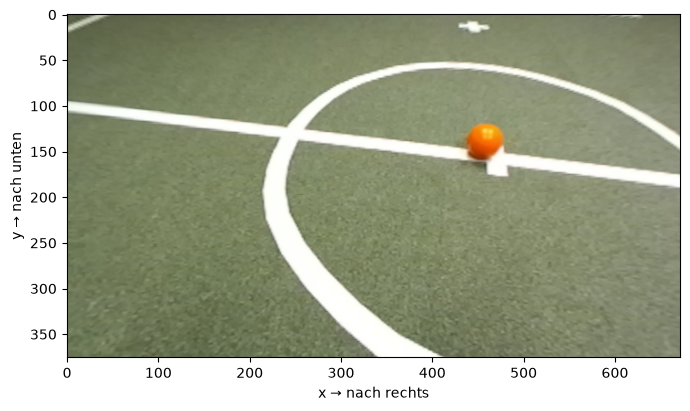

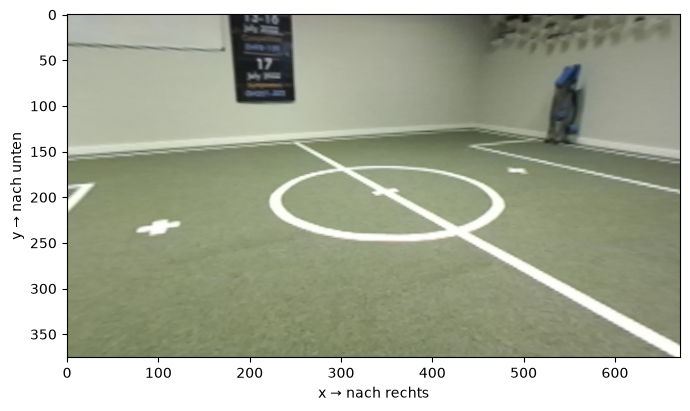

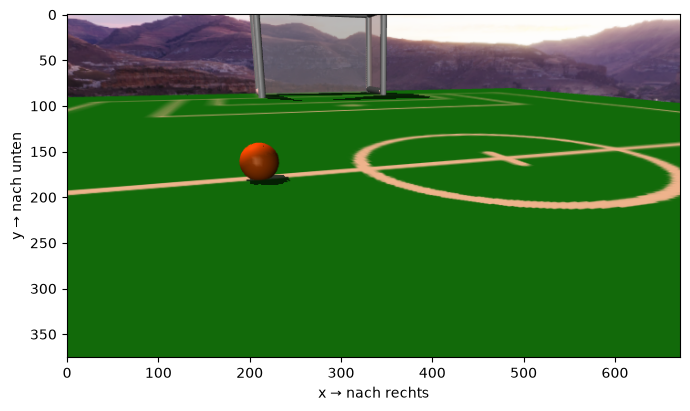

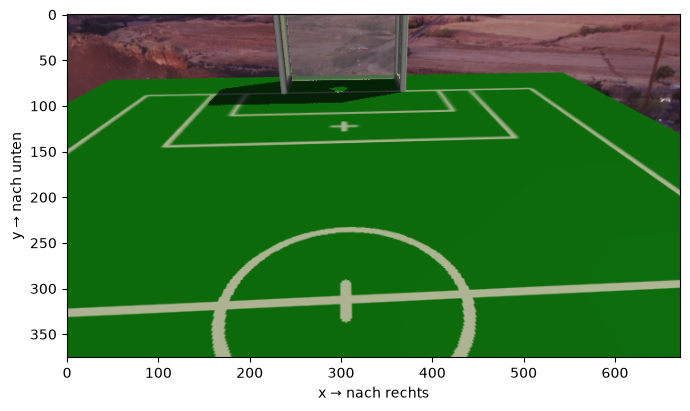

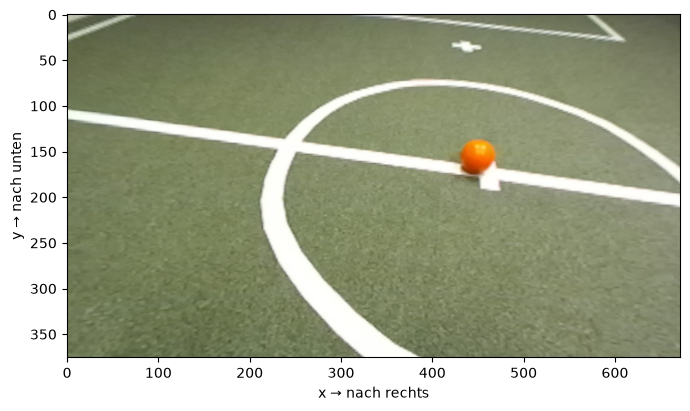

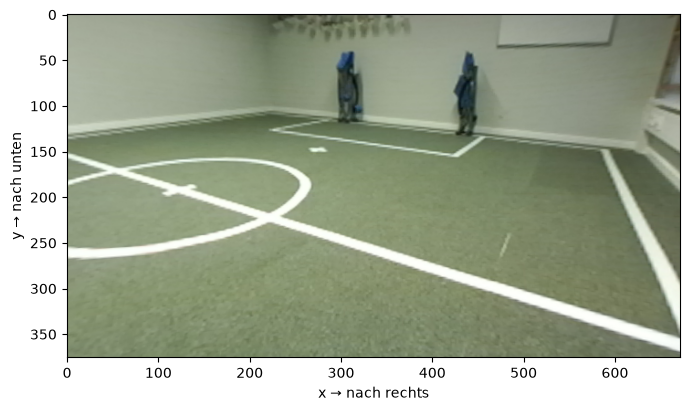

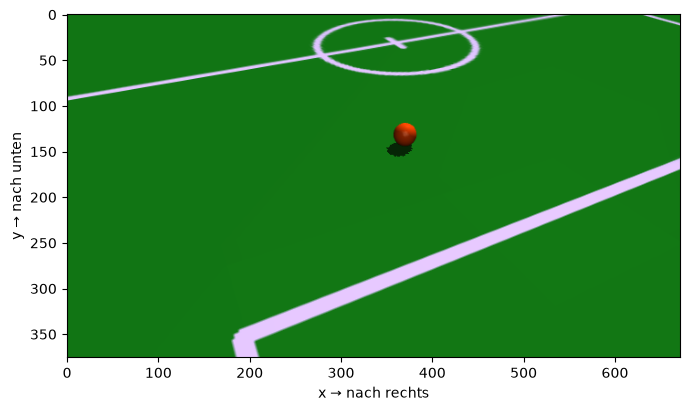

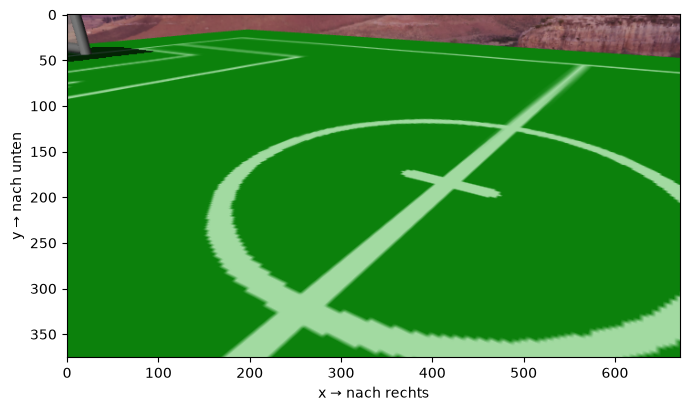

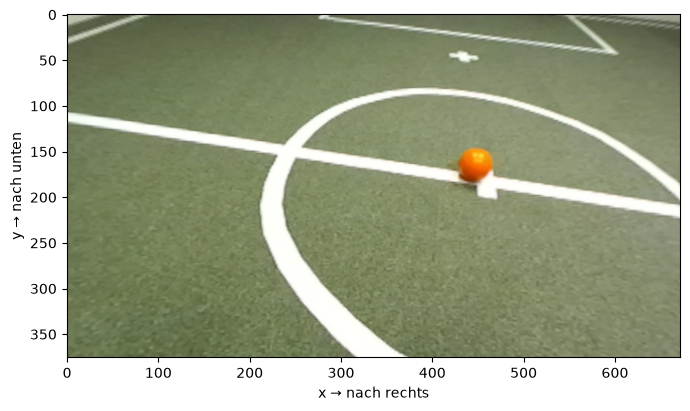

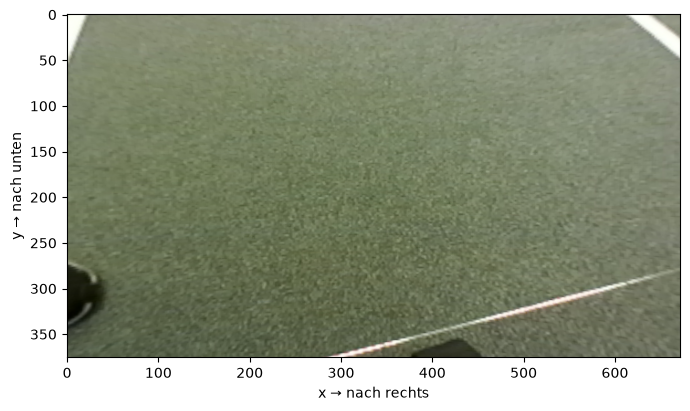

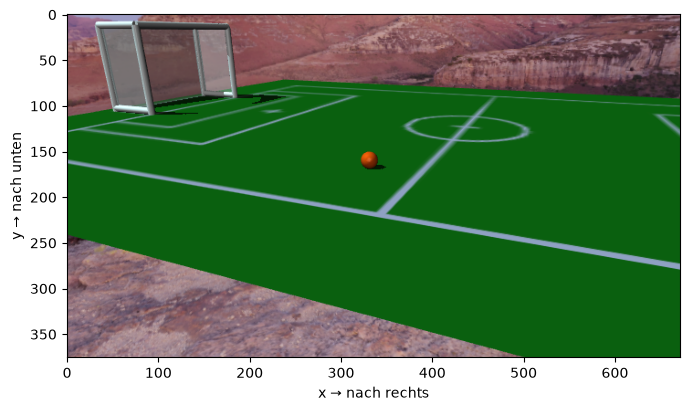

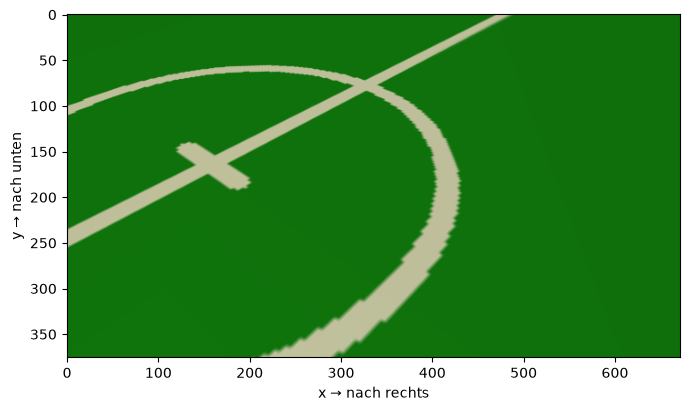

In [3]:
print(len(bilder))

for bild in bilder:
    bild_anzeigen(bild)

Ein Bild besteht aus **Pixeln**. Jedes Pixel enthält die Farbanteile **R**ot, **G**rün und **B**lau.

Wähle ein Bild mit Ball, indem du den Index in `bilder[0]` änderst.
Der Ursprung liegt oben links: **x wächst nach rechts, y nach unten**.
`bild[y, x]` gibt die Farbe des Pixels in Zeile `y` und Spalte `x` an.
**Achtung: erst `y`, dann `x`!**

**Frage:** Ändere `x` und `y`, bis das Kreuz auf dem Ball sitzt.
Wie unterscheiden sich die Zahlen von Ball, Boden und weißer Linie?

RGB: [134 144 107]


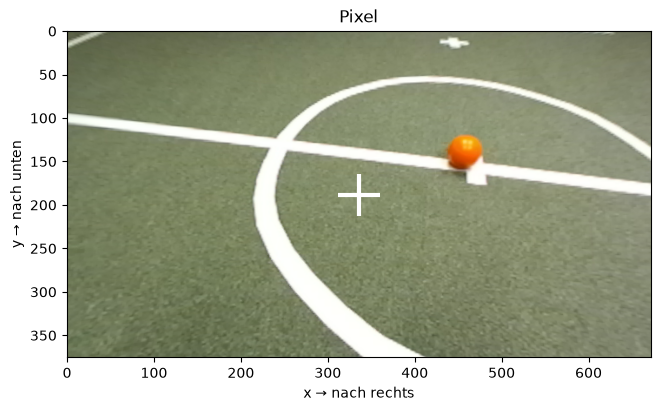

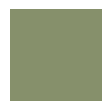

In [4]:
bild = bilder[0]
hoehe, breite = bild.shape[:2]
x = breite // 2
y = hoehe // 2
farbe = bild[y, x]
print("RGB:", farbe)
bild_anzeigen(bild, "Pixel", x, y)
farbfeld = np.full((16, 16, 3), farbe, dtype=np.uint8)
bild_anzeigen(farbfeld, "", groesse=(1, 1), achsen=False)

## Teil 1: Die Kanäle einzeln anschauen

Jedes Pixel hat 3 Zahlen. Man nennt sie **Kanäle**: Kanal 0 = Rot, Kanal 1 = Grün, Kanal 2 = Blau.

`bild[:, :, 0]` heißt: alle Zeilen, alle Spalten, aber nur Kanal 0. Das Ergebnis ist ein Graubild:
**hell = viel Rot, dunkel = wenig Rot**.

**Aufgabe 1a:** Zeige auch den Grün- und den Blau-Kanal an.

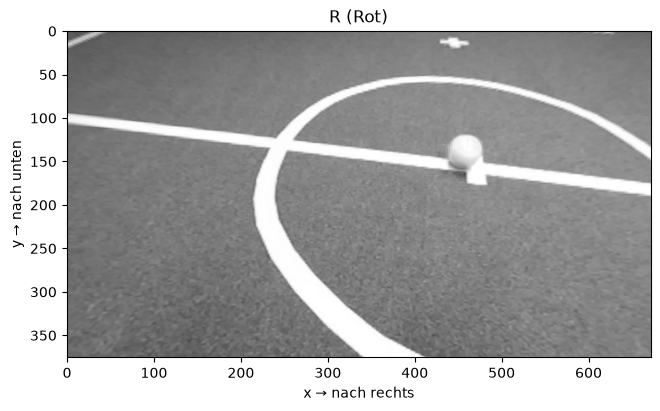

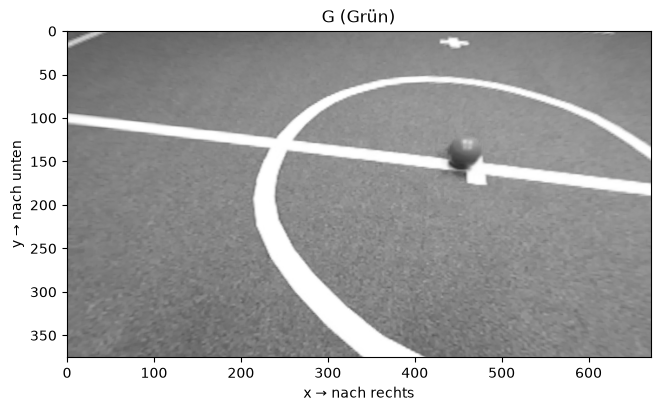

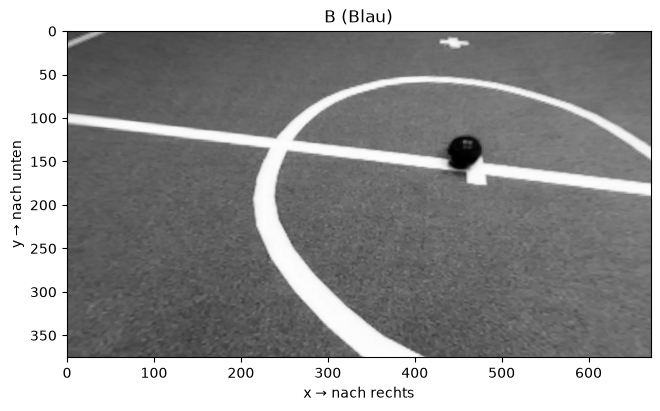

In [5]:
bild_anzeigen(bild[:, :, 0], "R (Rot)")
bild_anzeigen(bild[:, :, 1], "G (Grün)")
bild_anzeigen(bild[:, :, 2], "B (Blau)")

Ein orangefarbener Ball hat im Schatten andere RGB-Werte als im Licht.
Mit einzelnen Grenzen für Rot, Grün und Blau ist es deshalb schwierig, dieselbe Farbe
bei unterschiedlicher Helligkeit auszuwählen.

**HSV trennt Farbton, Sättigung und Helligkeit.** Wir können nach Orange suchen,
ohne für jeden Helligkeitsunterschied neue RGB-Grenzen festzulegen.
Mit der Sättigung unterscheiden wir kräftige Farben von Grau und Weiß.
Das macht die Auswahl übersichtlicher, aber nicht unabhängig von der Beleuchtung.
`zu_hsv(bild)` rechnet die Darstellung um:

- **H – Farbton** (*Hue*): die Position rund um den Zylinder, etwa Rot, Orange, Grün oder Blau.
- **S – Sättigung** (*Saturation*): von grau in der Mitte zu kräftiger Farbe am Rand.
- **V – Helligkeit** (*Value*): von dunkel unten zu hell oben.

<img src="abbildungen/hsv-zylinder.png" alt="HSV-Zylinder mit Farbton, Sättigung und Helligkeit" width="320">

<small>SharkD, [Wikimedia Commons](https://en.wikipedia.org/wiki/File:HSV_color_solid_cylinder_saturation_gray.png),
[CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), unverändert.</small>

Unsere Hilfsfunktion verwendet für alle Kanäle den vollen Ganzzahlbereich des Bildes.
Die H-Werte sind deshalb keine Winkel in Grad. Der Farbton läuft im Kreis: Rot liegt an beiden Enden.

**Aufgabe 1b:** Speichere die Kanäle von `hsv` in `h`, `s` und `v` und zeige sie an.

**Frage:** In welchem der Graubilder hebt sich der Ball am besten ab? Wie sehen die weißen Linien aus?

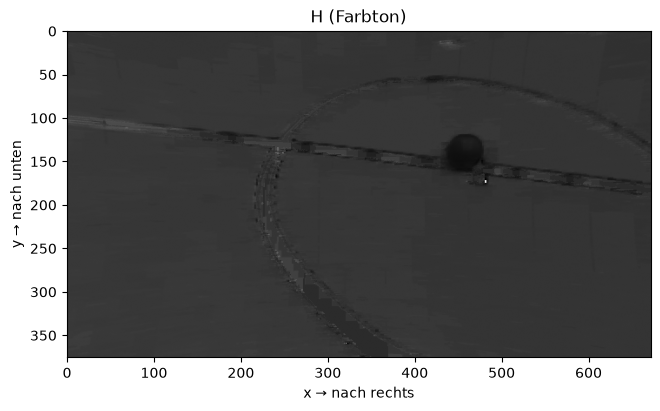

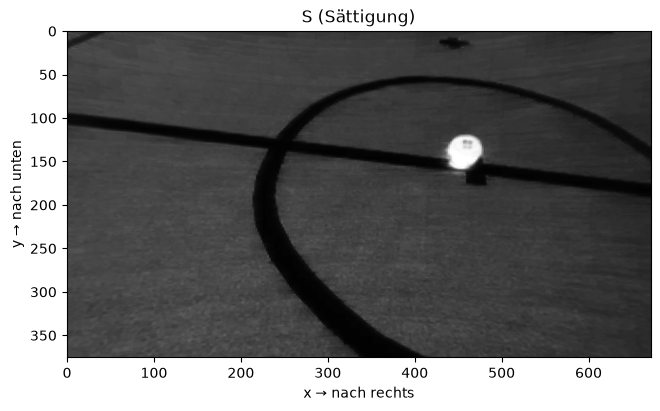

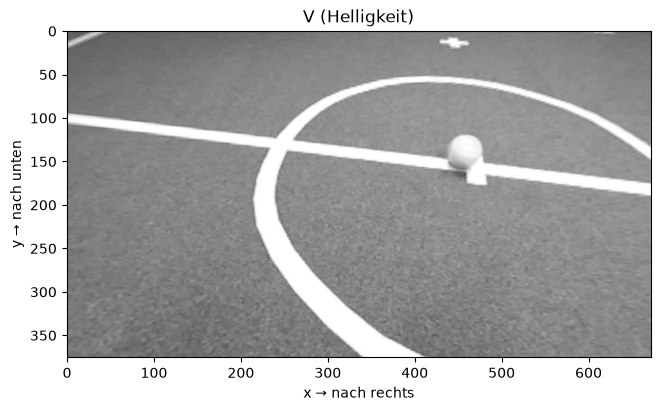

In [6]:
hsv = zu_hsv(bild)
h = hsv[:, :, 0]  # Farbton
s = hsv[:, :, 1]  # Sättigung
v = hsv[:, :, 2]  # Helligkeit

bild_anzeigen(h, "H (Farbton)")
bild_anzeigen(s, "S (Sättigung)")
bild_anzeigen(v, "V (Helligkeit)")

In [7]:
print("HSV-Kanäle: ganze Zahlen von", np.iinfo(hsv.dtype).min, "bis", np.iinfo(hsv.dtype).max)

HSV-Kanäle: ganze Zahlen von 0 bis 255


## Teil 2: Das Histogramm

Wie oft kommt jeder Farbton vor? Dafür erstellen wir ein **Histogramm** (eine Strichliste):
für jeden Wert von 0 bis 255 zählen wir, wie viele Pixel ihn haben.

`h == 17` sagt für jedes Pixel *Ja* oder *Nein*. `np.sum(h == 17)` zählt die *Ja*s.

**Aufgabe 2:** Vervollständige die Funktion.

Danach zeigt `histogramm_anzeigen` die Liste als Balkendiagramm.
`h.size` ist die Anzahl aller Pixel. Daran siehst du, ob du richtig gezählt hast: Zusammen müssen es genau so viele sein.

252672 Pixel gezählt, es sollten 252672 sein.


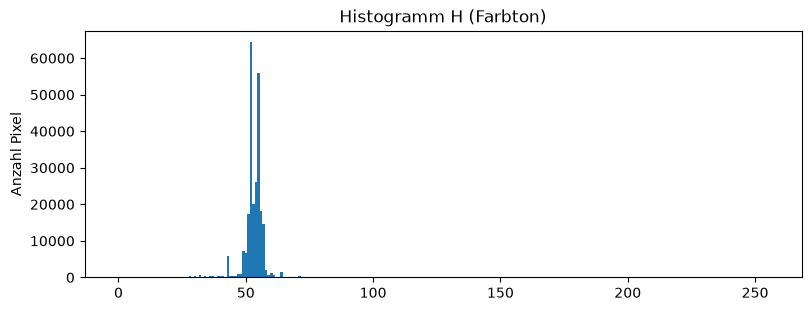

In [8]:
def histogramm(kanal):
    liste = []
    for wert in range(256):
        anzahl = np.sum(kanal == wert)
        liste.append(anzahl)
    return liste


histogramm_h = histogramm(h)
print(np.sum(histogramm_h), "Pixel gezählt, es sollten", h.size, "sein.")
histogramm_anzeigen(histogramm_h, "Histogramm H (Farbton)")

**Frage:** Welcher Berg gehört zum Boden, welcher zum Ball? Zwischen welchen Werten liegt der Ball?

## Teil 3: Die Maske

Eine **Maske** (wie eine Schablone) sagt für jedes Pixel `True` (**markiert**: passt zu unseren Grenzen) oder `False` (nicht markiert).
`bild_anzeigen` zeigt markierte Pixel weiß, alle anderen schwarz.
Zwei Bedingungen verbindest du mit `&`, jede in Klammern: `(h >= 100) & (h <= 120)`

**Aufgabe 3a:** Trage deine Grenzen ein und ergänze die zweite Bedingung.

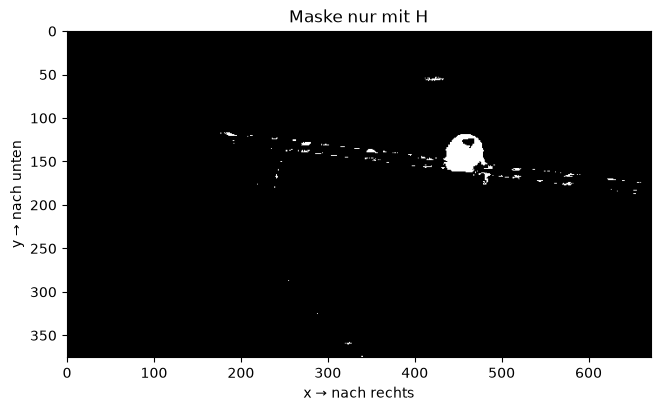

In [9]:
h_von = 0
h_bis = 28

maske = (h >= h_von) & (h <= h_bis)
bild_anzeigen(maske, "Maske nur mit H")

**Frage:** Ist nur der Ball markiert? Probiere auch andere Bilder (oben `bild = bilder[2]`). Was rutscht noch durch, und warum?

**Aufgabe 3b:** Weiß und Grau haben keinen richtigen Farbton, aber eine kleine Sättigung `s`.
Schau dir das Histogramm von `s` an und ergänze eine dritte Bedingung.

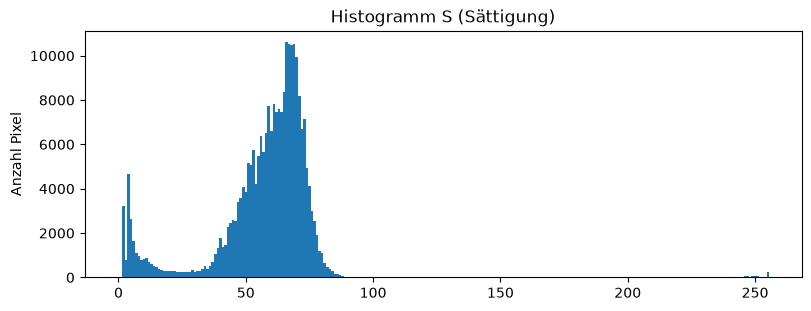

In [10]:
histogramm_s = histogramm(s)
histogramm_anzeigen(histogramm_s, "Histogramm S (Sättigung)")

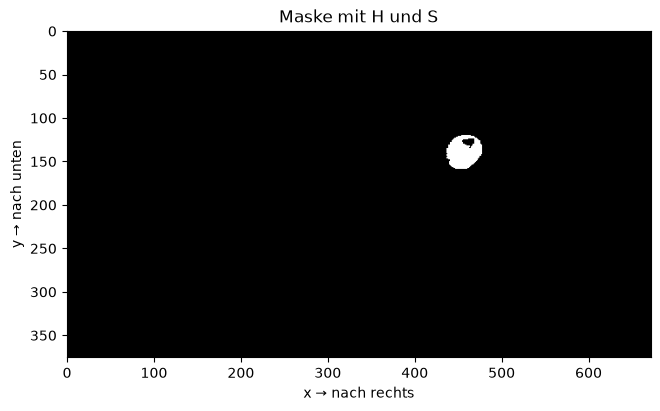

In [11]:
s_min = 140

maske = (h >= h_von) & (h <= h_bis) & (s >= s_min)
bild_anzeigen(maske, "Maske mit H und S")

**Aufgabe 3c:** Bei sehr dunklen Pixeln ist die Farbe als Erkennungsmerkmal oft wenig hilfreich.
Untersuche `v` und ergänze eine untere Helligkeitsgrenze.
Vergleiche die Maske mit und ohne diese Bedingung: Welche zusätzlichen Stellen werden markiert?

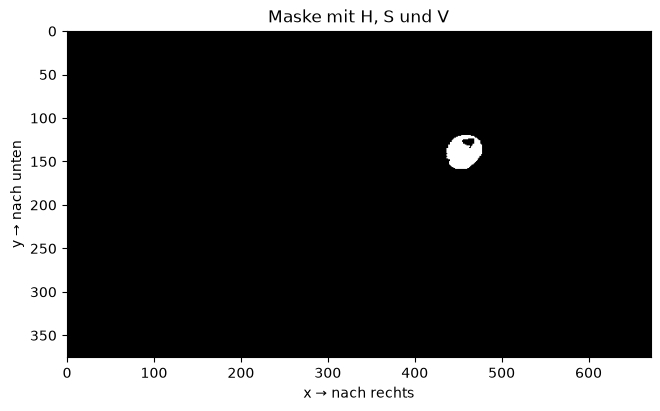

In [12]:
v_min = 80
maske = (h >= h_von) & (h <= h_bis) & (s >= s_min) & (v >= v_min)
bild_anzeigen(maske, "Maske mit H, S und V")

## Teil 4: Wo ist der Ball?

Der **Mittelwert** ist die Summe der Werte geteilt durch ihre Anzahl.
Wenn die markierten Pixel gleichmäßig über den Ball verteilt sind, liegt ihr Mittelwert
ungefähr in der Ballmitte. Schatten, Verdeckung und fremde Flecken können ihn verschieben.

`np.nonzero(maske)` liefert die Zeilen und Spalten aller markierten Pixel.
`spalten.mean()` berechnet den Mittelwert der Spalten; mit den Zeilen geht es genauso.
Eine leere Maske hat keine Ballmitte. Prüfe deshalb vorher, ob überhaupt Pixel markiert sind.

**Aufgabe 4a:** Berechne die Ballmitte `x` und `y`.

1163 markierte Pixel


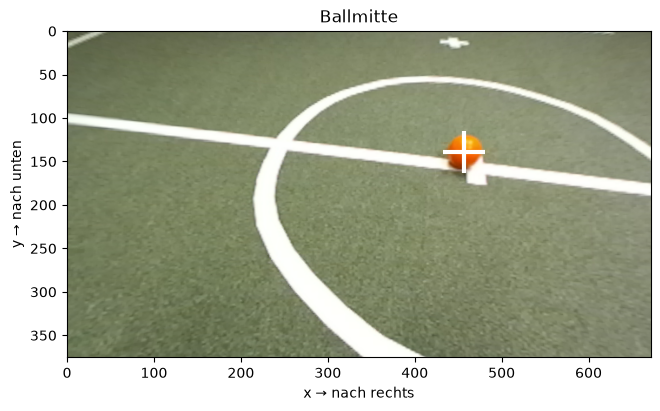

In [13]:
zeilen, spalten = np.nonzero(maske)
print(len(spalten), "markierte Pixel")
x, y = None, None
if len(spalten) > 0:
    x = spalten.mean()
    y = zeilen.mean()
else:
    print("Keine passenden Pixel – probiere ein anderes Bild oder andere Grenzen.")
bild_anzeigen(bild, "Ballmitte", x, y)

### Die Bounding Box finden

Die Mitte beschreibt noch nicht die Größe des Balls. Wir suchen ein umschließendes
Rechteck, eine **Bounding Box**, als Tupel `(links, oben, rechts, unten)`.
Links und rechts sind x-Koordinaten, oben und unten y-Koordinaten.
Die rechte und untere Grenze liegen direkt hinter den eingeschlossenen Pixeln.

Zuerst suchen wir den unteren Rand des Rechtecks.
**Idee:** Wie viele markierte Pixel hat jede Zeile? Wir erstellen ein **Zeilenhistogramm**.
`np.sum(maske[zeile, :])` zählt die markierten Pixel dieser Zeile.

**Aufgabe 4b:** Berechne für jede Zeile die Anzahl markierter Pixel.

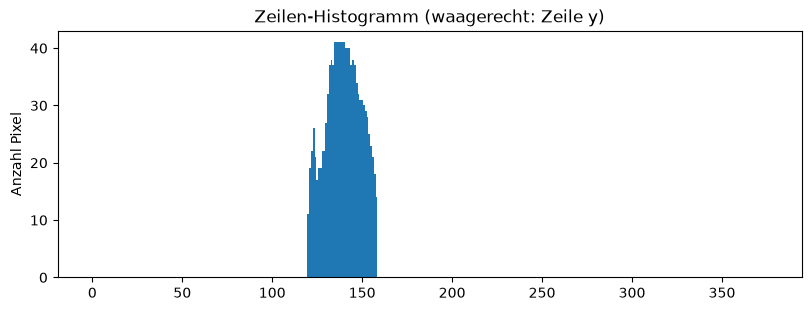

In [14]:
zeilen_histogramm = []
for zeile in range(len(maske)):
    anzahl = np.sum(maske[zeile, :])
    zeilen_histogramm.append(anzahl)

histogramm_anzeigen(zeilen_histogramm, "Zeilen-Histogramm (waagerecht: Zeile y)")

**Frage:** Wo im Diagramm ist der Ball? Wo ist sein unterer Rand?

Wir starten bei der Ballmitte und laufen **nach unten**, solange die nächste Zeile noch
genügend markierte Pixel hat. Die Grenze legen wir mit `min_pro_zeile` fest.
Am Bildrand müssen wir ebenfalls aufhören.

Die Schleife braucht beide Bedingungen:
- `unten + 1 < len(zeilen_histogramm)`: Es gibt noch eine nächste Zeile.
- `zeilen_histogramm[unten + 1] >= min_pro_zeile`: Diese Zeile enthält genügend markierte Pixel.

`and` verbindet hier einzelne Bedingungen; `&` verbindet die Vergleiche für ganze Pixelarrays.

**Aufgabe 4c:** Ergänze die Bedingung der `while`-Schleife.

In [15]:
min_pro_zeile = 3
unten = None
if len(spalten) > 0:
    unten = int(zeilen.mean())
    while unten + 1 < len(zeilen_histogramm) and zeilen_histogramm[unten + 1] >= min_pro_zeile:
        unten = unten + 1
print("Unterer Rand:", unten)

Unterer Rand: 158


**Frage:** Warum stört ein einzelnes falsch markiertes Pixel weit unter dem Ball jetzt nicht mehr?

### Die übrigen Grenzen ergänzen

**Aufgabe 4d:** Zähle nun auch die markierten Pixel je **Spalte**.
Suche von der Mitte aus in alle Richtungen die letzte ausreichend markierte Zeile bzw. Spalte.
Die Suche nach unten ist schon vorgegeben; ergänze oben, links und rechts.

Das Ergebnis ist ein einzelnes Tupel `(links, oben, rechts, unten)`.
Wenn kein Ball gefunden wird, verwenden wir `None`.

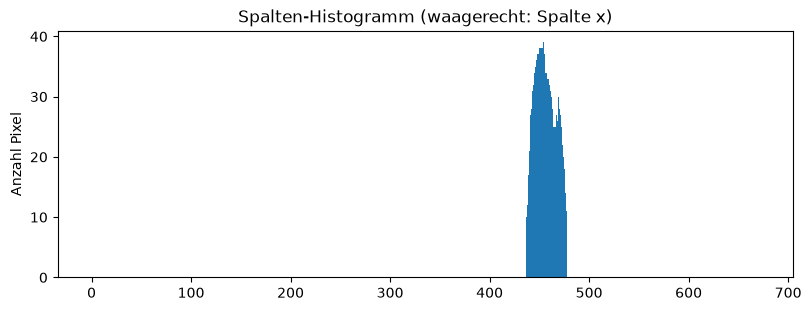

In [16]:
spalten_histogramm = []
for spalte in range(maske.shape[1]):
    anzahl = np.sum(maske[:, spalte])
    spalten_histogramm.append(anzahl)
histogramm_anzeigen(spalten_histogramm, "Spalten-Histogramm (waagerecht: Spalte x)")

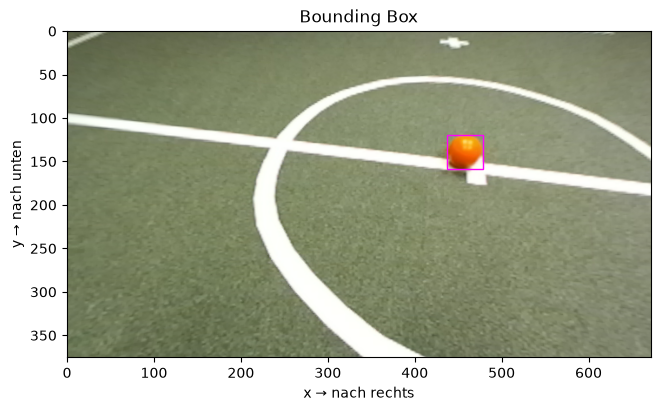

In [17]:
box = None
if len(spalten) > 0:
    x, y = int(spalten.mean()), int(zeilen.mean())
    links = rechts = x
    oben = unten = y
    if zeilen_histogramm[y] >= min_pro_zeile and spalten_histogramm[x] >= min_pro_zeile:
        while unten + 1 < len(zeilen_histogramm) and zeilen_histogramm[unten + 1] >= min_pro_zeile:
            unten += 1
        while oben > 0 and zeilen_histogramm[oben - 1] >= min_pro_zeile:
            oben -= 1
        while rechts + 1 < len(spalten_histogramm) and spalten_histogramm[rechts + 1] >= min_pro_zeile:
            rechts += 1
        while links > 0 and spalten_histogramm[links - 1] >= min_pro_zeile:
            links -= 1
        box = (links, oben, rechts + 1, unten + 1)
bild_anzeigen(bild, "Bounding Box", box=box)

## Teil 5: Die Schritte in einer Funktion zusammenfassen

**Aufgabe 5:** Setze deine Schritte aus `aufgabe.ipynb` zu `detect_balls` zusammen:
HSV berechnen → Maske bilden → markierte Pixel zählen → Mitte bestimmen → Grenzen suchen.
Sind weniger als `min_pixel` Pixel markiert, gib `None` zurück.
Prüfe auch, ob die Zeile und Spalte durch die berechnete Mitte genügend Pixel enthalten.

Der Detektor erhält Bilder in **BGR** statt RGB. Deshalb beginnt die Funktion mit
`zu_hsv(image_bgr, bgr=True)`. Mit `bgr=True` kennt die Hilfsfunktion die Kanalreihenfolge.
Die HSV-Bereiche sind dieselben wie in unseren Übungen.

Die Ausgabe ist **ein Tupel `(links, oben, rechts, unten)` oder `None`**, falls kein Ball
gefunden wird. Wir erwarten höchstens eine Box pro Bild.
`detektor_anzeigen` übernimmt die BGR-Umwandlung unserer RGB-Übungsbilder.

In [ ]:
def detect_balls(image_bgr: np.ndarray) -> tuple[int, int, int, int] | None:
    h_von, h_bis = 0, 28
    s_min, v_min = 140, 80
    min_pixel = 100
    min_pro_zeile = 3
    hsv = zu_hsv(image_bgr, bgr=True)
    h = hsv[:, :, 0]
    s = hsv[:, :, 1]
    v = hsv[:, :, 2]
    maske = (h >= h_von) & (h <= h_bis) & (s >= s_min) & (v >= v_min)
    zeilen, spalten = np.nonzero(maske)
    if len(spalten) < min_pixel:
        return None

    zeilen_histogramm = []
    for zeile in range(maske.shape[0]):
        zeilen_histogramm.append(np.sum(maske[zeile, :]))
    spalten_histogramm = []
    for spalte in range(maske.shape[1]):
        spalten_histogramm.append(np.sum(maske[:, spalte]))

    x = int(spalten.mean())
    y = int(zeilen.mean())
    if zeilen_histogramm[y] < min_pro_zeile or spalten_histogramm[x] < min_pro_zeile:
        return None

    links = rechts = x
    oben = unten = y
    while unten + 1 < len(zeilen_histogramm) and zeilen_histogramm[unten + 1] >= min_pro_zeile:
        unten += 1
    while oben > 0 and zeilen_histogramm[oben - 1] >= min_pro_zeile:
        oben -= 1
    while rechts + 1 < len(spalten_histogramm) and spalten_histogramm[rechts + 1] >= min_pro_zeile:
        rechts += 1
    while links > 0 and spalten_histogramm[links - 1] >= min_pro_zeile:
        links -= 1
    return (links, oben, rechts + 1, unten + 1)

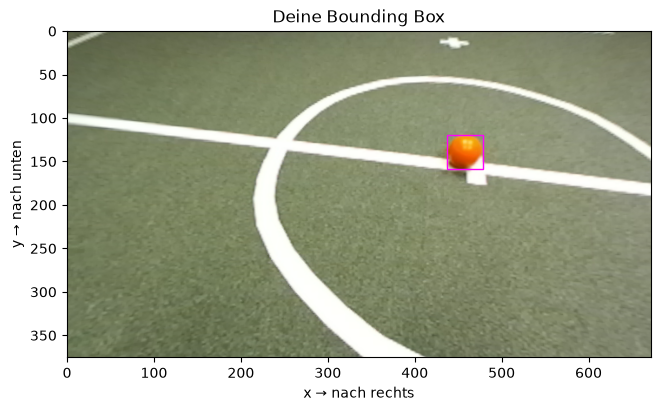

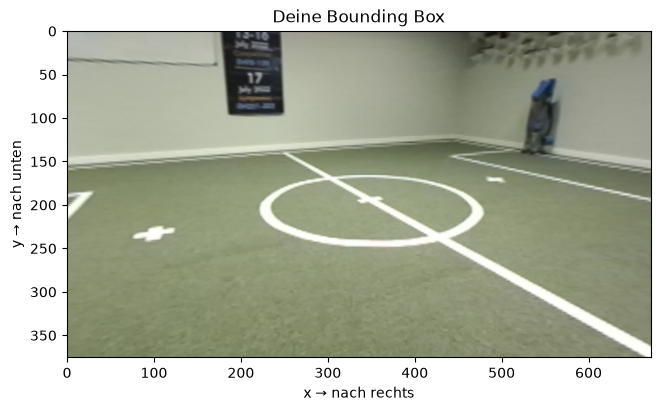

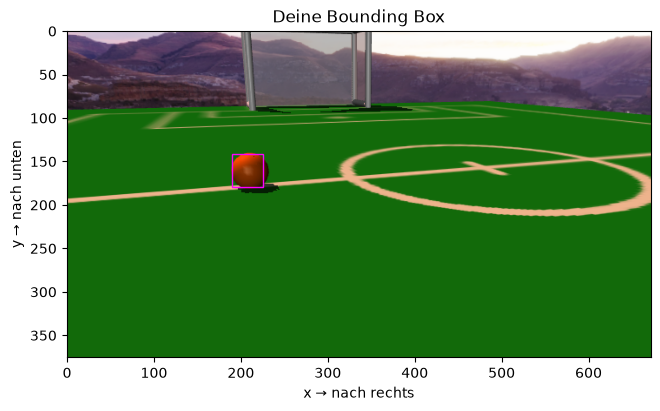

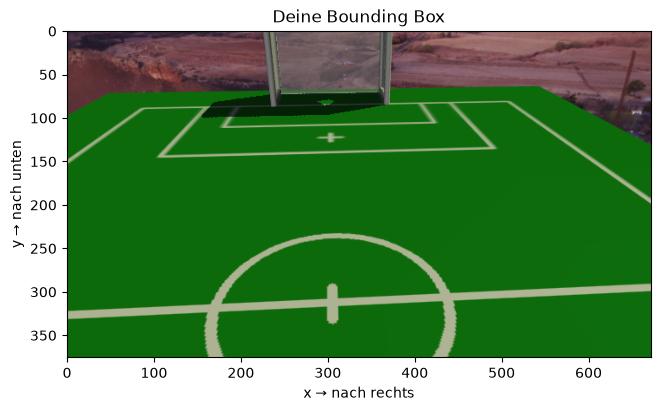

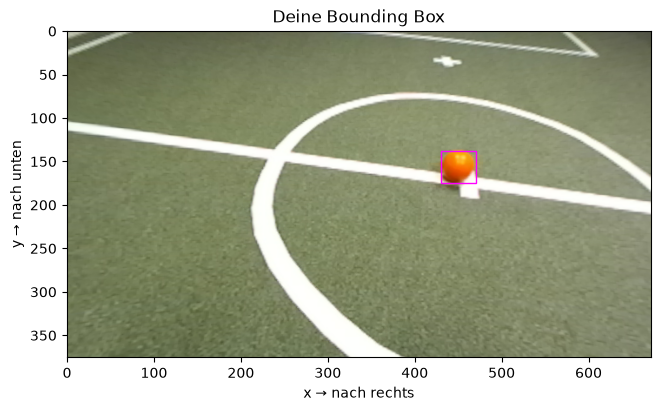

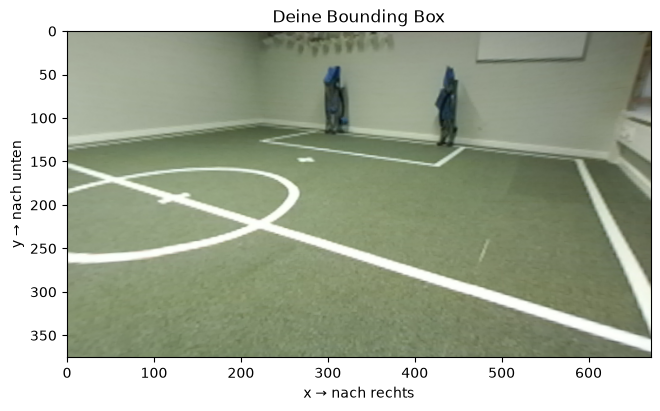

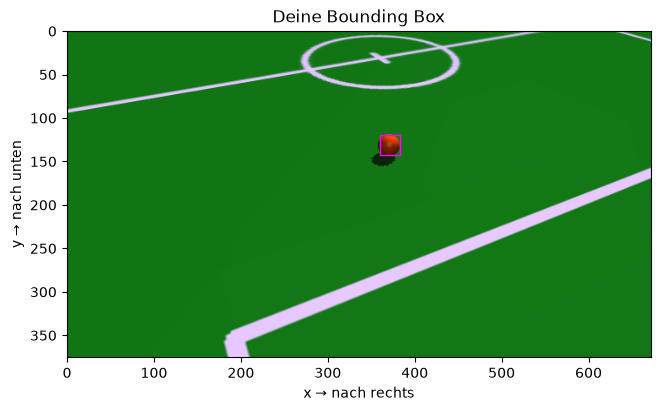

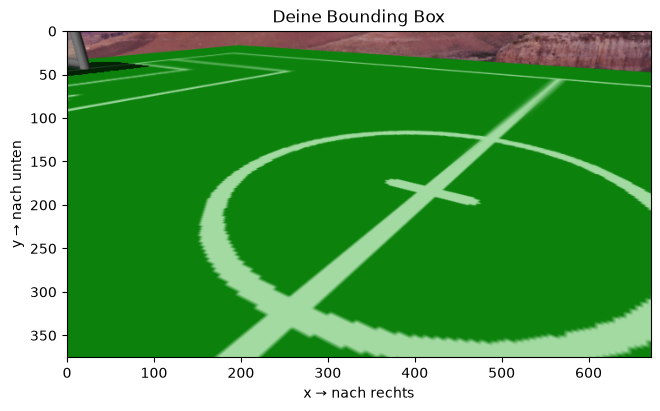

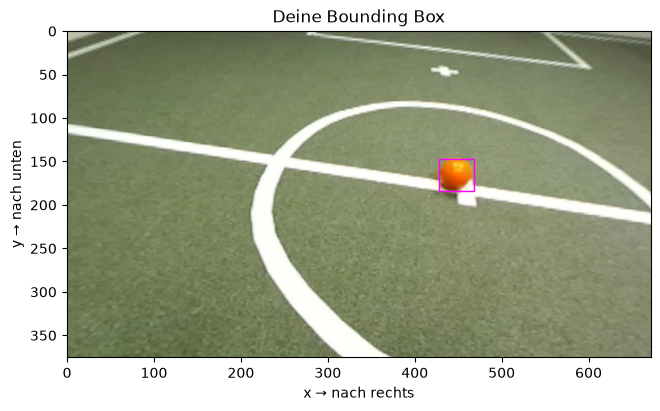

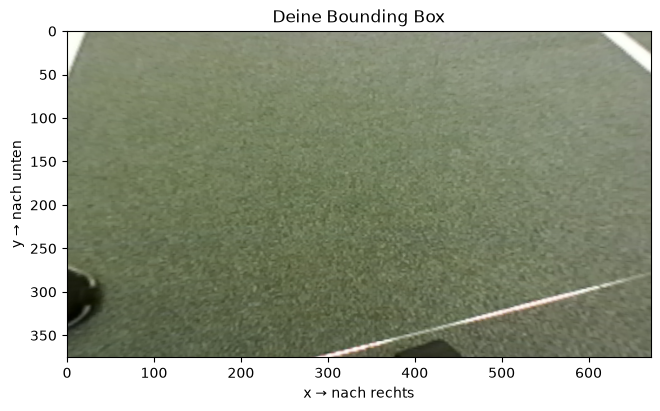

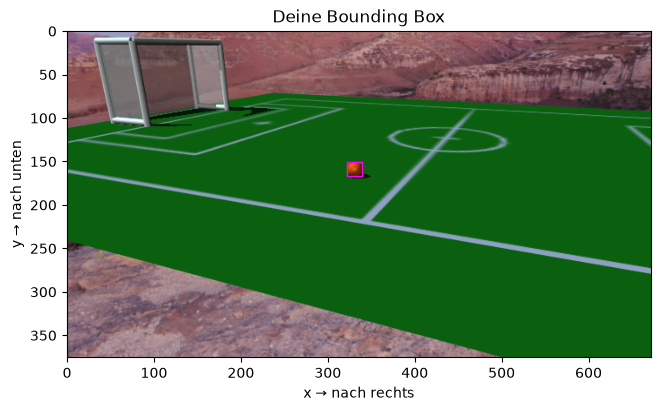

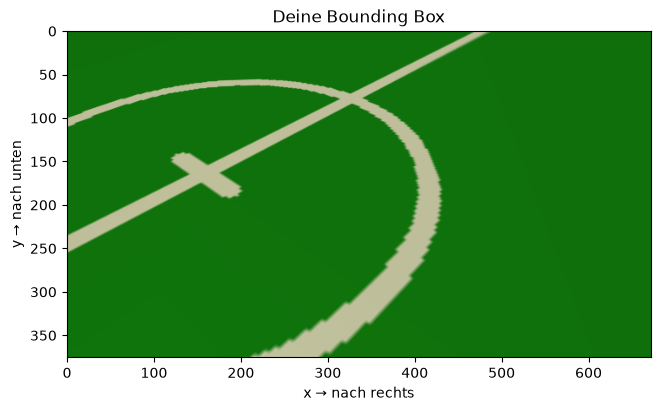

In [19]:
for bild in bilder:
    detektor_anzeigen(bild, detect_balls)

## Bonus: Liegt in der Mitte wirklich ein Ball?

**Denkanstoß:** Der Mittelwert berücksichtigt alle markierten Pixel.
Was passiert, wenn außer dem Ball noch andere Stellen markiert sind?
Und was, wenn mehrere Bälle im Bild liegen?

Die Mitte kann zwischen den Bällen oder neben dem eigentlichen Ball liegen.
Wir prüfen deshalb einen **Ausschnitt** der Maske rund um die berechnete Mitte.
Mit `bild[oben:unten, links:rechts]` erhältst du einen Ausschnitt.
Die untere und rechte Grenze gehören nicht mehr dazu.

In [20]:
print("Bildhöhe und Bildbreite:", bild.shape[:2])

Bildhöhe und Bildbreite: (376, 672)


Ein Quadrat um (`x`, `y`) mit Abstand `r` zu allen Seiten ist
`bild[y-r:y+r+1, x-r:x+r+1]`.
Am Bildrand beschränken wir die Grenzen mit `max` und `min`, damit keine negativen
Indizes vom anderen Ende des Bildes zählen.

**Bonus 1:** Schneide ein Quadrat um die Ballmitte aus und zeige es an.
Berechne anschließend in einem kleineren Quadrat der Maske den Anteil markierter Pixel.

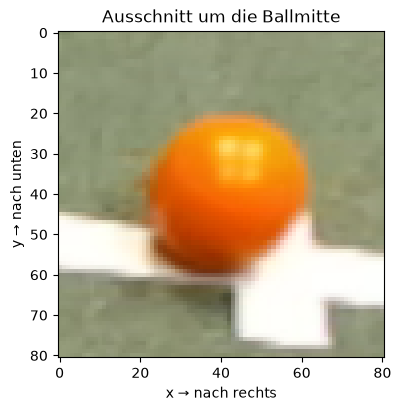

Anteil markiert: 1.0


In [21]:
bild = bilder[0]
hsv = zu_hsv(bild)
h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
maske = (h >= h_von) & (h <= h_bis) & (s >= s_min) & (v >= v_min)
zeilen, spalten = np.nonzero(maske)
x, y = None, None
if len(spalten) > 0:
    x, y = int(spalten.mean()), int(zeilen.mean())
    r = 40
    oben, unten = max(0, y - r), min(bild.shape[0], y + r + 1)
    links, rechts = max(0, x - r), min(bild.shape[1], x + r + 1)
    ausschnitt = bild[oben:unten, links:rechts]
    bild_anzeigen(ausschnitt, "Ausschnitt um die Ballmitte")

    r = 5
    quadrat = maske[max(0, y - r) : y + r + 1, max(0, x - r) : x + r + 1]
    anteil = np.sum(quadrat) / quadrat.size
    print("Anteil markiert:", anteil)
else:
    print("Kein Ausschnitt: Die Maske ist leer.")

**Bonus 2:** Lass das Quadrat wachsen, um den **Radius** des Balls abzuschätzen.

- Ist das Startquadrat nicht mindestens zur Hälfte markiert, liefert die Funktion keinen Radius.
- Sonst wächst `r`, solange noch genügend neue markierte Pixel hinzukommen.
- An allen Bildrändern muss die Suche stoppen. Dort ist der Radius nur unvollständig sichtbar.

Aus Mitte und Radius lässt sich ebenfalls ein umschließendes Quadrat bestimmen.
Vergleiche es mit der Bounding Box aus den Histogrammen.

Radius: 21


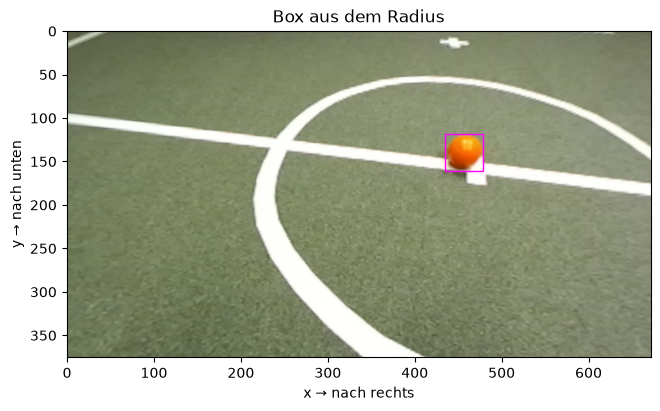

In [22]:
def ball_radius(maske, x, y, r=5, min_neu=4):
    if x is None or y is None or not (0 <= x < maske.shape[1] and 0 <= y < maske.shape[0]):
        return 0
    max_r = min(x, y, maske.shape[1] - 1 - x, maske.shape[0] - 1 - y)
    if max_r < r:
        return 0
    quadrat = maske[y - r : y + r + 1, x - r : x + r + 1]
    if np.sum(quadrat) < quadrat.size / 2:
        return 0
    while r < max_r:
        groesser = maske[y - r - 1 : y + r + 2, x - r - 1 : x + r + 2]
        neu = np.sum(groesser) - np.sum(quadrat)
        if neu < min_neu:
            break
        r += 1
        quadrat = groesser
    return r


r = ball_radius(maske, x, y)
print("Radius:", r)
if x is not None and y is not None:
    radius_box = None
    if r > 0:
        radius_box = (x - r, y - r, x + r + 1, y + r + 1)
    bild_anzeigen(bild, "Box aus dem Radius", box=radius_box)

**Bonus 3: Zwei Bälle.** `ball_verdoppeln(bild, maske, dx, dy)` aus `werkzeuge.py` kopiert alle markierten Pixel der Maske
um `dx` Pixel nach rechts und `dy` Pixel nach unten (negative Zahlen: nach links bzw. oben). So entsteht ein Bild mit zwei Bällen.

Wo landet jetzt die Mitte? Was sagt `ball_radius` dazu? Probiere verschiedene Abstände aus, auch so, dass sich die Bälle berühren.

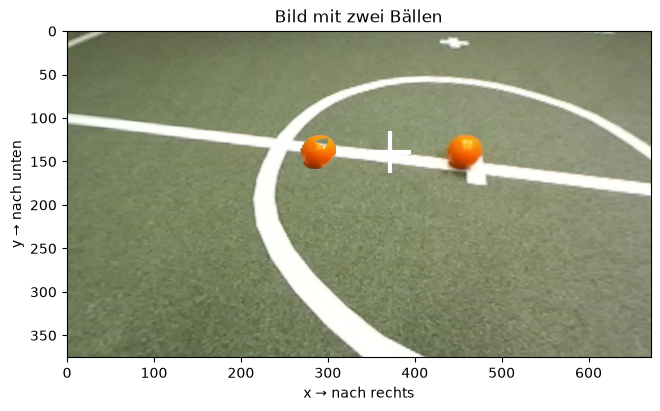

Radius: 0


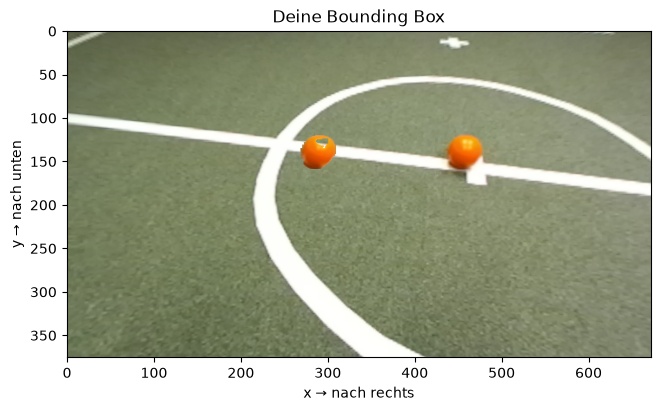

In [23]:
bild_zwei = ball_verdoppeln(bild, maske, -bild.shape[1] // 4, 0)
hsv = zu_hsv(bild_zwei)
h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
maske_zwei = (h >= h_von) & (h <= h_bis) & (s >= s_min) & (v >= v_min)
zeilen, spalten = np.nonzero(maske_zwei)
x, y = None, None
if len(spalten) > 0:
    x, y = int(spalten.mean()), int(zeilen.mean())
bild_anzeigen(bild_zwei, "Bild mit zwei Bällen", x, y)
print("Radius:", ball_radius(maske_zwei, x, y))
detektor_anzeigen(bild_zwei, detect_balls)

## Zum Schluss: Wie gut funktioniert unsere Lösung?

Die bisherigen Bilder waren **Trainingsbilder**: An ihnen dürfen wir Regeln entwickeln.
Prüfe jetzt die gesamte Trainingsmenge, nicht nur die kleine Auswahl.

Vorgegebene **Groundtruth-Boxen** zeigen, wo die Bälle tatsächlich liegen.
Für einen Treffer muss deine Box ausreichend mit einer Referenzbox überlappen.
Die feste Auswertung verwendet dafür die gemeinsame Fläche geteilt durch die insgesamt
bedeckte Fläche (**IoU**). Jeder Ball und jede Vorhersage zählen höchstens zu einem Treffer.

- **TP:** richtig gefundene Bälle; **FP:** Fehlmeldungen; **FN:** übersehene Bälle.
- **Precision:** Wie viele der Meldungen stimmen?
- **Recall:** Wie viele der vorhandenen Bälle werden gefunden?
- **F1:** ein gemeinsamer Wert für Precision und Recall.

Achte auf die getrennten Ergebnisse für `real` (Kamera) und `simulation`.
In den Fehlerbildern sind Groundtruth-Boxen grün und deine Vorhersagen magenta.

orange/train · overall: {'tp': 129, 'fp': 11, 'fn': 31, 'precision': 0.9214285714285714, 'recall': 0.80625, 'f1': 0.86}
  Bilder: 320; positive Bilder: 160
orange/train · real: {'tp': 75, 'fp': 2, 'fn': 5, 'precision': 0.974025974025974, 'recall': 0.9375, 'f1': 0.9554140127388535}
  Bilder: 160; positive Bilder: 80
orange/train · simulation: {'tp': 54, 'fp': 9, 'fn': 26, 'precision': 0.8571428571428571, 'recall': 0.675, 'f1': 0.7552447552447552}
  Bilder: 160; positive Bilder: 80


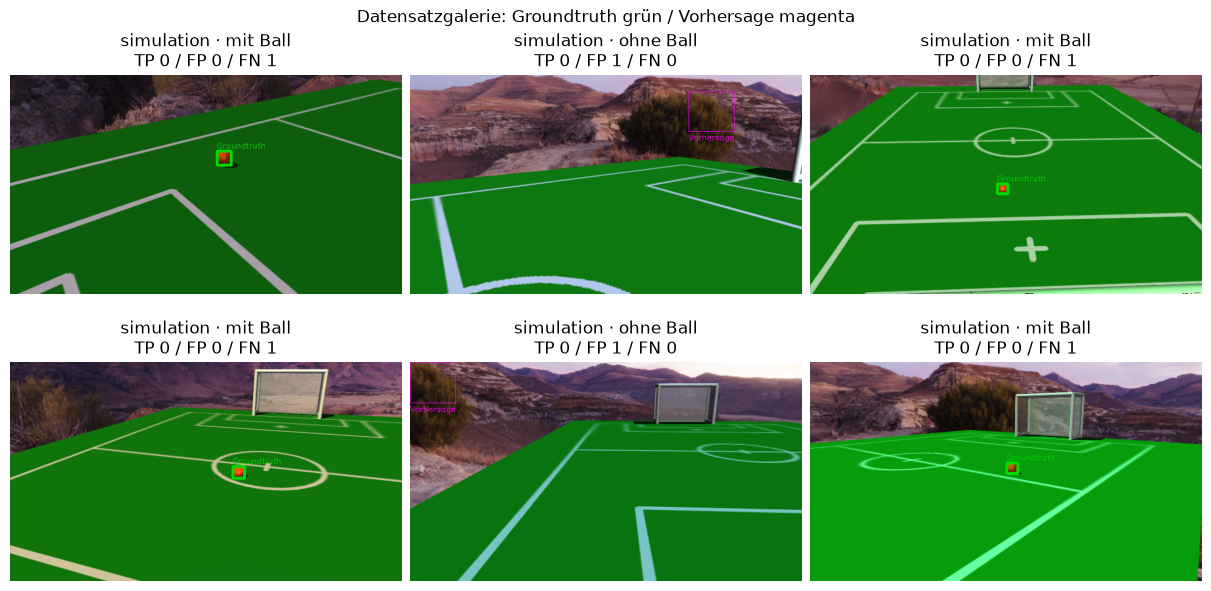

In [24]:
train_result = auswerten(detect_balls)

**Abschlusstest:** Erst wenn deine Lösung feststeht, setze `RUN_FINAL_TEST` auf `True`.
Die **Testbilder** wurden für die Abschlussprüfung zurückgehalten.
Wenn du danach weiter verbesserst, ist derselbe Test kein unabhängiger Vergleich mehr.

In [25]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    test_result = auswerten(detect_balls, split="test")

**Transfer:** Was passiert bei weißen oder gemusterten Bällen?
Formuliere eine Vermutung und setze dann `RUN_TRANSFER` auf `True`.
Verwende die fertige Funktion unverändert.

In [28]:
RUN_TRANSFER = False
if RUN_TRANSFER:
    transfer_result = auswerten(detect_balls, datensatz="realistic", split="test")

**Rückblick:** Welche Änderung hat geholfen? Welche Annahme scheitert bei anderen Bällen?
Wie würdest du das Verfahren erweitern, damit es mehrere getrennte Bälle findet?